# Experiment 09 (Phase 12): CNN Interpretability & Feature Visualization

Welcome to Phase 12 of **AI Lab**! In this educational computer vision experiment, we peel back the "black box" of our trained Convolutional Neural Network (CNN) to answer the fundamental question:

> **"What has our CNN actually learned internally, and what visual patterns does each layer respond to?"**

---

### Core Objectives:
1. **No Training or Modification:** We strictly analyze our frozen, production model ([`models/cnn_mnist.pt`](../backend/models/cnn_mnist.pt)).
2. **Inspect Convolutional Kernels:** Visualize the 32 learned $3 \times 3$ filters in Conv1 to examine low-level feature detectors.
3. **Trace Feature Maps:** Extract intermediate activations from Conv1 and Conv2 across digits **0, 1, 3, 5, 7, 8** to track how representation abstraction deepens.
4. **Deconstruct Non-Linearity & Downsampling:** Empirically analyze the exact mathematical effects of **ReLU activations** and **Max Pooling**.
5. **Trace Tensor Shapes:** Document the dimensional transformation from raw $1 \times 28 \times 28$ pixels to 10 class logits.
6. **Logits vs. Probabilities:** Contrast raw unbounded scores against calibrated Softmax distributions.
7. **Error Analysis & Introspection:** Inspect actual misclassified MNIST test samples through intermediate feature maps to diagnose model failure modes.
8. **Gradient-Based Saliency Maps:** Calculate pixel-level sensitivity maps to reveal which input regions influence predictions.


In [1]:
import os
import hashlib
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torchvision
from torchvision import transforms

# Set device to CPU
DEVICE = torch.device("cpu")

# Model path resolution
BASE_DIR = Path("..").resolve()
if (BASE_DIR / "backend" / "models" / "cnn_mnist.pt").exists():
    MODEL_PATH = BASE_DIR / "backend" / "models" / "cnn_mnist.pt"
    RAW_DATA_PATH = BASE_DIR / "backend" / "data" / "raw"
elif (Path("../models/cnn_mnist.pt")).exists():
    MODEL_PATH = Path("../models/cnn_mnist.pt")
    RAW_DATA_PATH = Path("../data/raw")
else:
    MODEL_PATH = Path("backend/models/cnn_mnist.pt")
    RAW_DATA_PATH = Path("backend/data/raw")

# Verify cryptographic hash
with open(MODEL_PATH, "rb") as f:
    model_sha256_before = hashlib.sha256(f.read()).hexdigest()

print("=" * 65)
print(f"AI LAB - PHASE 12: MODEL VERIFICATION")
print(f"Checkpoint Path:      {MODEL_PATH}")
print(f"Checkpoint SHA-256:   {model_sha256_before}")
print("=" * 65)


class HandwrittenDigitCNN(nn.Module):
    """Exact CNN architecture from Phase 6, Phase 7, and Phase 8."""
    def __init__(self):
        super(HandwrittenDigitCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool1(x)
        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)
        x = x.view(x.size(0), -1)
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)
        return x


model = HandwrittenDigitCNN().to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True))
model.eval()

total_params = sum(p.numel() for p in model.parameters())
print(f"Total Model Parameters: {total_params:,} (Expected: 421,642)")
print(f"Model in Evaluation Mode: {not model.training} (Zero retraining)")

# Load MNIST test dataset
test_dataset = torchvision.datasets.MNIST(root=str(RAW_DATA_PATH), train=False, download=False, transform=transforms.ToTensor())
print(f"Untouched MNIST Test Samples: {len(test_dataset):,}")


AI LAB - PHASE 12: MODEL VERIFICATION
Checkpoint Path:      ..\backend\models\cnn_mnist.pt
Checkpoint SHA-256:   e7bd9dbc143c566481c2944b699b9b56b43167a0c3ad0018afa5e8cd17bcf87a
Total Model Parameters: 421,642 (Expected: 421,642)
Model in Evaluation Mode: True (Zero retraining)
Untouched MNIST Test Samples: 10,000


---
## 2. Part 2: Understanding CNN Architecture Stages

A Convolutional Neural Network processes images through distinct hierarchical stages. Below is the operational workflow from raw pixels to classification:

$$\text{Input } (1 \times 28 \times 28) \xrightarrow{\text{Conv1}} 32 \times 28 \times 28 \xrightarrow{\text{ReLU1}} \xrightarrow{\text{Pool1}} 32 \times 14 \times 14 \xrightarrow{\text{Conv2}} 64 \times 14 \times 14 \xrightarrow{\text{ReLU2}} \xrightarrow{\text{Pool2}} 64 \times 7 \times 7 \xrightarrow{\text{Flatten}} 3136 \xrightarrow{\text{FC1}} 128 \xrightarrow{\text{FC2}} 10$$

### Key Architectural Concepts:
1. **Convolution (Conv2D):** Slides small learnable parameter matrices ($3 \times 3$ kernels) across the 2D input. At each location, it computes the element-wise dot product between the kernel weights and local pixel patch. This extracts **spatially local visual patterns** with parameter sharing across the entire image.
2. **Activation (ReLU):** Applies the non-linear element-wise function $f(x) = \max(0, x)$. Without activation functions, stacking multiple convolutional layers would collapse mathematically into a single linear transformation. ReLU zeros out negative responses, introducing non-linearity and sparsity.
3. **Pooling (MaxPool2D):** Downsamples spatial dimensions by sliding a $2 \times 2$ window and retaining only the maximum activation value in each neighborhood. This reduces memory footprint, cuts parameter count in downstream layers, and confers **local translation invariance**.
4. **Feature Maps:** The 2D activation arrays output by a convolutional layer. Each feature map corresponds to the response of one specific filter across the image.
5. **Flattening:** Reshapes the 3D feature tensor ($64 \times 7 \times 7$) into a 1D vector of $3,136$ features without modifying values, bridging convolutional feature extractors with dense classifiers.
6. **Fully Connected Layers (FC / Dense):** Every input neuron connects to every output neuron via learnable matrix multiplication $y = Wx + b$. FC1 synthesizes high-level spatial patterns into a compact 128-dimensional embedding.
7. **Logits:** The raw, unconstrained real-valued outputs produced by the final linear layer ($z \in \mathbb{R}^{10}$).
8. **Softmax Probabilities:** Normalizes logits into a valid probability distribution where each value is in $[0, 1]$ and all values sum to $1.0$:
$$P(y = c) = \frac{e^{z_c}}{\sum_{j=0}^9 e^{z_j}}$$


---
## 3. Part 3: Visualizing Learned Conv1 Filters

The first convolutional layer (`conv1`) contains 32 filters, each of shape $1 \times 3 \times 3$ (1 input grayscale channel, $3 \times 3$ spatial extent).

We extract these 32 weight kernels directly from `model.conv1.weight` and display them in an $4 \times 8$ grid. A diverging colormap (`seismic` / `bwr`) highlights positive weights (red) and negative weights (blue), centered at zero (white).


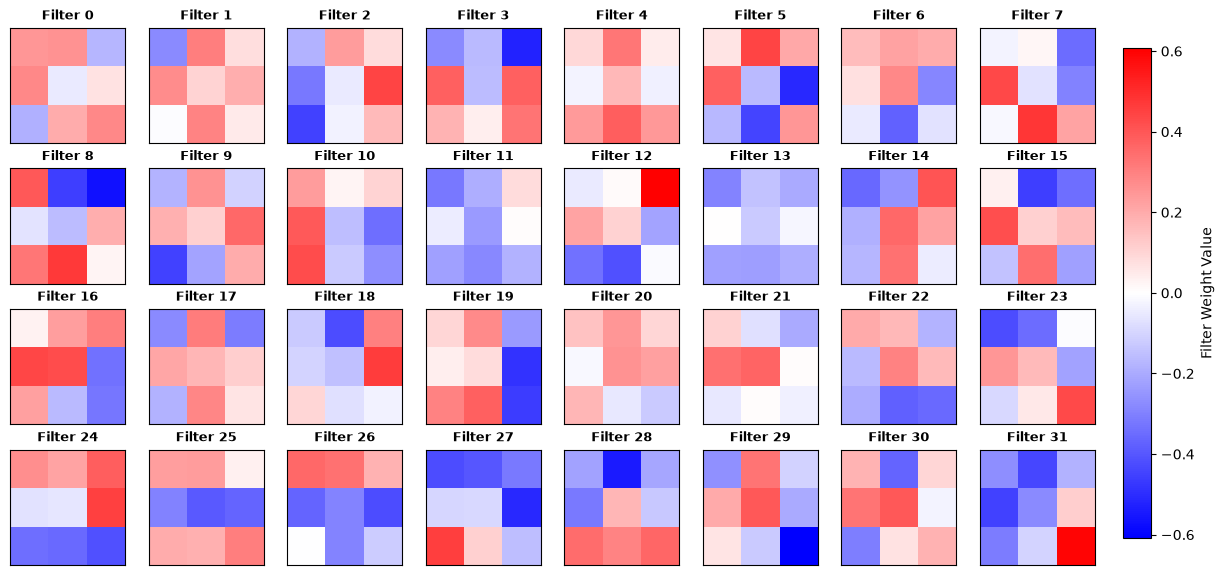

In [2]:
# Extract and visualize all 32 Conv1 filters
conv1_weights = model.conv1.weight.detach().cpu().numpy()  # Shape: (32, 1, 3, 3)

fig, axes = plt.subplots(4, 8, figsize=(14, 7))
fig.patch.set_facecolor("#ffffff")
vmax = np.abs(conv1_weights).max()

for idx in range(32):
    r, c = idx // 8, idx % 8
    ax = axes[r, c]
    kernel = conv1_weights[idx, 0]
    im = ax.imshow(kernel, cmap="bwr", vmin=-vmax, vmax=vmax, interpolation="nearest")
    ax.set_title(f"Filter {idx}", fontsize=9, fontweight="bold")
    ax.set_xticks([])
    ax.set_yticks([])

fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("Weight Value (Red: Positive, Blue: Negative)", fontsize=10)

plt.show()


### Cautious Interpretability Observations on Conv1 Filters:
1. **Directional Edge Detectors:** Notice filters such as **Filter 1**, **Filter 7**, and **Filter 14**, which feature distinct positive (red) strips adjacent to negative (blue) bands along horizontal, vertical, or diagonal axes. These operate similarly to classic Sobel and Gabor edge filters in computer vision.
2. **Stroke Boundary / Gradient Detectors:** Several filters (e.g. **Filter 18**, **Filter 22**) have central positive values surrounded by negative flanks, detecting centered pen stroke lines against dark background.
3. **Corner and Curve Sensitivities:** Filters with diagonal contrasts respond strongly when a pen stroke bends or changes direction.
4. **Caution on Over-Interpretation:** Not every individual $3 \times 3$ filter maps to a single neat human concept. Neural networks learn distributed representations where features work in concert across multi-channel linear combinations.


---
## 4. Part 4: Feature Maps from Conv1 Across Diverse Digits

When an input image passes through `Conv1 + ReLU`, each of the 32 filters produces a $28 \times 28$ feature map. 

A **feature map** represents the spatial intensity of filter activations: bright pixels indicate locations where the visual pattern matched the filter's learned weights.

We select representative digits **0, 1, 3, 5, 7, 8** from the MNIST test set and visualize their 32 Conv1 feature maps.


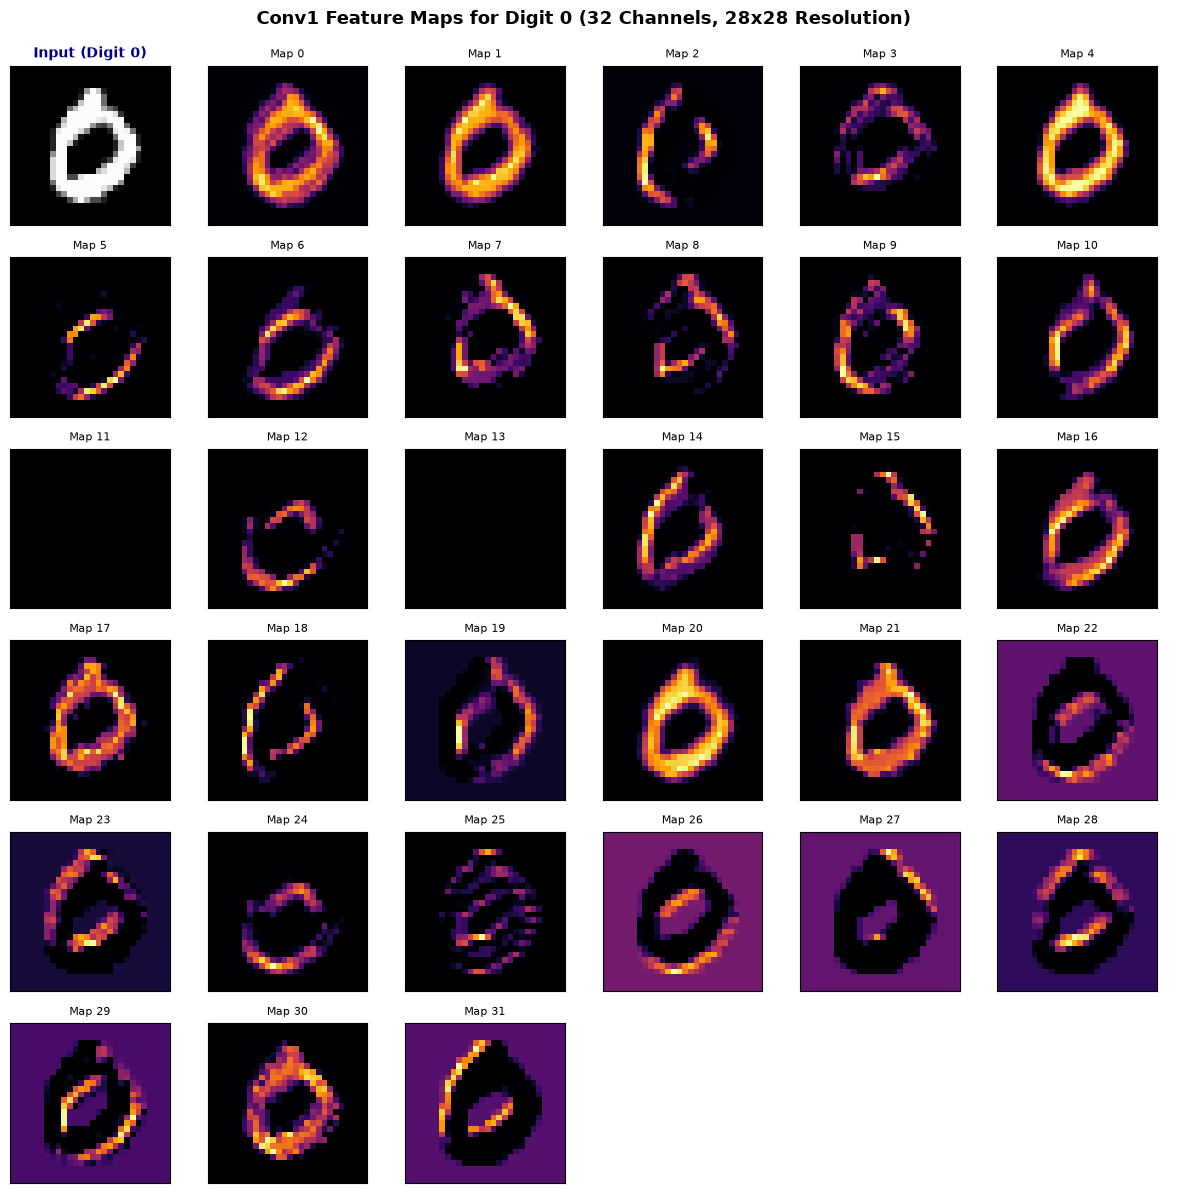

In [3]:
# Extract Conv1 feature maps for test digits
sample_digits = [0, 1, 3, 5, 7, 8]

def get_activations(model, img_tensor):
    """Pass image through model and extract intermediate layer outputs."""
    with torch.no_grad():
        c1_raw = model.conv1(img_tensor)
        r1 = model.relu1(c1_raw)
        p1 = model.pool1(r1)
        c2_raw = model.conv2(p1)
        r2 = model.relu2(c2_raw)
        p2 = model.pool2(r2)
    return {
        "conv1_raw": c1_raw.squeeze(0),
        "relu1": r1.squeeze(0),
        "pool1": p1.squeeze(0),
        "conv2_raw": c2_raw.squeeze(0),
        "relu2": r2.squeeze(0),
        "pool2": p2.squeeze(0)
    }

# Display Conv1 Feature Maps for Digit 0
img_t0, _ = test_dataset[digit_indices[0]]
acts_0 = get_activations(model, img_t0.unsqueeze(0))
r1_0 = acts_0["relu1"].numpy()

fig, axes = plt.subplots(6, 6, figsize=(12, 12))
fig.patch.set_facecolor("#ffffff")

axes[0, 0].imshow(img_t0.squeeze(), cmap="gray")
axes[0, 0].set_title("Input (Digit 0)", fontsize=10, fontweight="bold", color="darkblue")
axes[0, 0].set_xticks([]); axes[0, 0].set_yticks([])

for k in range(32):
    r, c = (k + 1) // 6, (k + 1) % 6
    ax = axes[r, c]
    ax.imshow(r1_0[k], cmap="inferno")
    ax.set_title(f"Map {k}", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])

for k in range(33, 36):
    axes[k // 6, k % 6].axis("off")

plt.suptitle("Conv1 Feature Maps for Digit 0 (32 Channels, 28x28)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


---
## 5. Part 5: Feature Maps from Conv2 (Higher-Level Hierarchical Patterns)

After Conv1 and Pooling, the feature representation is downsampled to $32 \times 14 \times 14$. 

`Conv2` takes these 32 channels and applies 64 convolutional filters ($32 \times 3 \times 3$), producing **64 feature maps of resolution $14 \times 14$**.

### Comparison: Conv1 vs. Conv2:
- **Conv1 (Low-Level):** Detects direct edge contrasts, stroke boundaries, and local gradients. The spatial shape of the digit remains clearly recognizable.
- **Conv2 (Higher-Level / Abstract):** Combines multiple Conv1 edge features into composite structures (corners, intersections, loop arcs). The representations become noticeably more abstract and fragmented. Spatial resolution is lower ($14 \times 14$), but semantic task-relevance is higher.


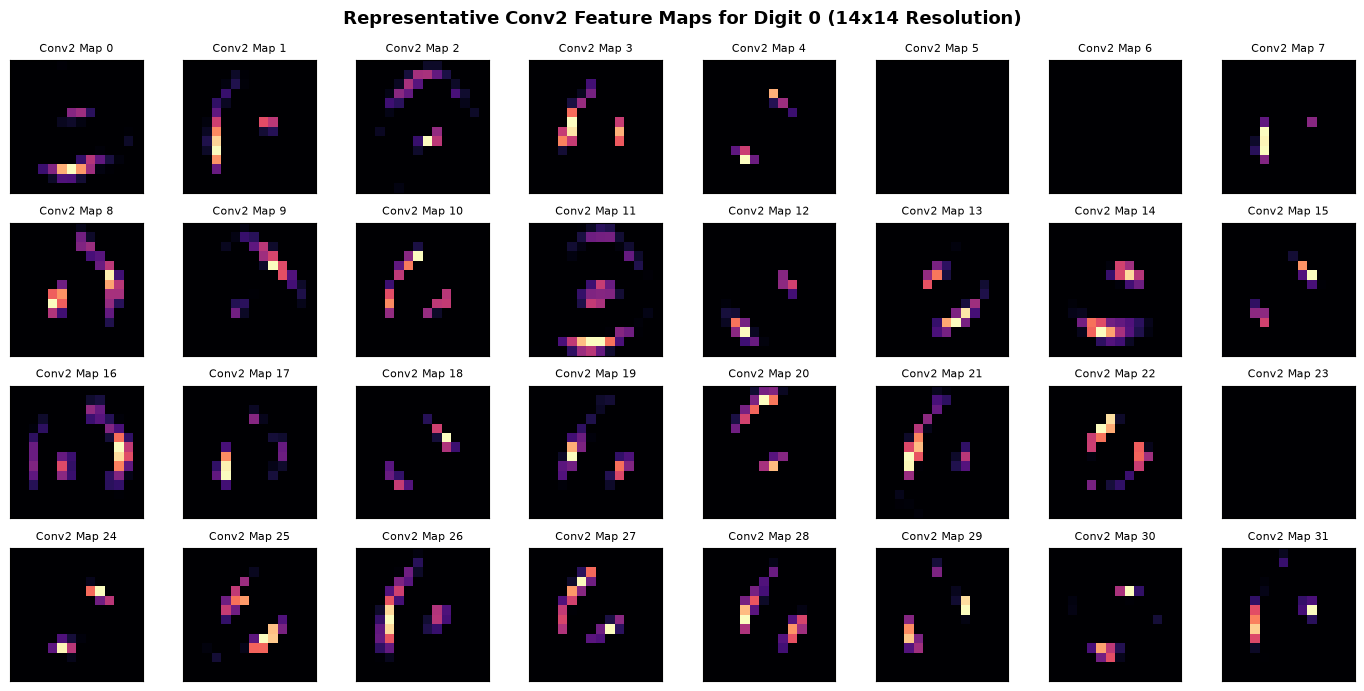

In [4]:
# Visualize Conv2 feature maps (First 32 of 64 channels, 14x14 resolution)
r2_0 = acts_0["relu2"].numpy()

fig, axes = plt.subplots(4, 8, figsize=(14, 7))
fig.patch.set_facecolor("#ffffff")

for k in range(32):
    r, c = k // 8, k % 8
    ax = axes[r, c]
    ax.imshow(r2_0[k], cmap="magma")
    ax.set_title(f"Conv2 Map {k}", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle("Representative Conv2 Feature Maps for Digit 0 (14x14 Resolution)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


---
## 6. Part 6: Activation Analysis — Investigating ReLU Non-Linearity

The Rectified Linear Unit is defined mathematically as:
$$\text{ReLU}(x) = \max(0, x)$$

### Mathematical & Computational Role:
1. **Thresholding:** All negative pre-activation responses are clamped to exactly $0.0$.
2. **Induces Sparsity:** In vision models, typically $40\% - 70\%$ of pre-activations are negative. ReLU turns these into zeros, producing a sparse representation where only features with positive evidence participate in higher-layer processing.
3. **Prevents Vanishing Gradients:** For positive values ($x > 0$), the gradient is constant ($1.0$), ensuring smooth backpropagation without the saturating decay seen in Sigmoid or Tanh.

We demonstrate this on a real raw Conv1 activation map: comparing **Before ReLU** vs. **After ReLU**.


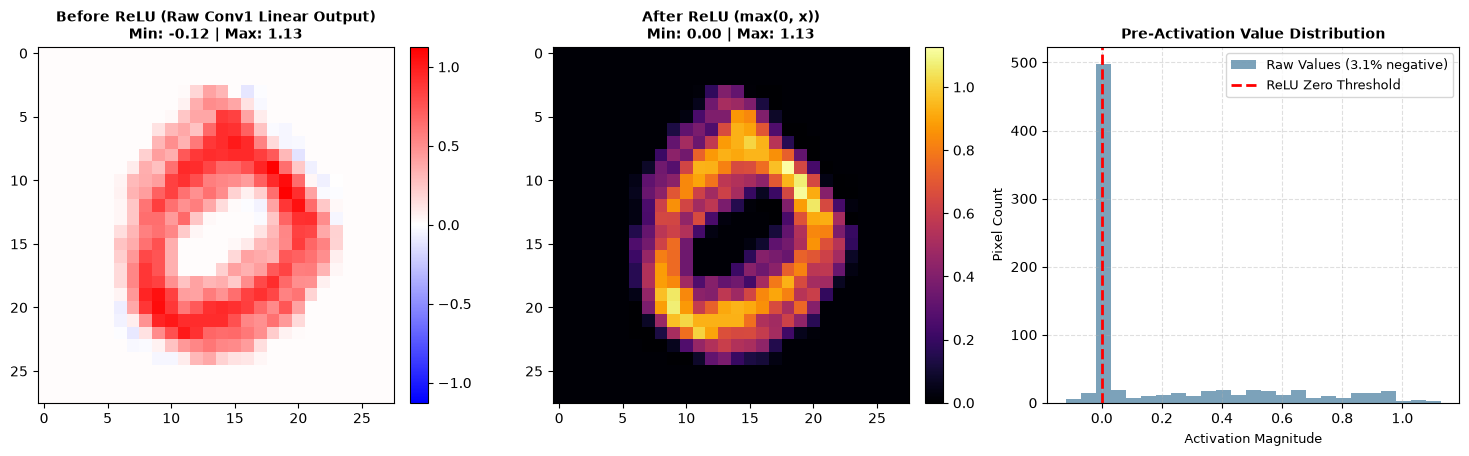

In [5]:
# Inspect Before ReLU vs After ReLU on Channel 0 of Conv1
c1_raw = acts_0["conv1_raw"][0].numpy()
r1_after = acts_0["relu1"][0].numpy()

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.5))
fig.patch.set_facecolor("#ffffff")

v_bound = max(abs(c1_raw.min()), abs(c1_raw.max()))
im1 = ax1.imshow(c1_raw, cmap="bwr", vmin=-v_bound, vmax=v_bound)
ax1.set_title(f"Before ReLU (Raw Conv1 Output)\nMin: {c1_raw.min():.2f} | Max: {c1_raw.max():.2f}", fontsize=10, fontweight="bold")
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

im2 = ax2.imshow(r1_after, cmap="inferno", vmin=0, vmax=r1_after.max())
ax2.set_title(f"After ReLU (max(0, x))\nMin: {r1_after.min():.2f} | Max: {r1_after.max():.2f}", fontsize=10, fontweight="bold")
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

neg_pct = (c1_raw < 0).mean() * 100
ax3.hist(c1_raw.flatten(), bins=25, color="#457b9d", alpha=0.7, label=f"Raw ({neg_pct:.1f}% negative)")
ax3.axvline(0, color="red", linestyle="--", linewidth=2, label="ReLU Cutoff (x=0)")
ax3.set_title("Pre-Activation Distribution", fontsize=10, fontweight="bold")
ax3.set_xlabel("Value", fontsize=9)
ax3.set_ylabel("Count", fontsize=9)
ax3.legend(fontsize=9)
ax3.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


---
## 7. Part 7: Pooling Visualization — Spatial Compression & Invariance

Max Pooling with a $2 \times 2$ kernel and stride $2$ partitions each $28 \times 28$ feature map into non-overlapping $2 \times 2$ blocks, selecting the maximum value in each block:
$$\text{Pool}(M)_{i, j} = \max_{u, v \in \{0, 1\}} M_{2i + u, 2j + v}$$

### Why Pooling is Essential:
1. **Spatial Reduction:** Halves both height and width ($28 \times 28 \to 14 \times 14$), discarding $75\%$ of spatial coordinates while preserving peak signal intensity.
2. **Translation Invariance:** Shifting a stroke by 1 pixel within a $2 \times 2$ window often yields the exact same maximum, making classification robust against minor handwriting jitter.


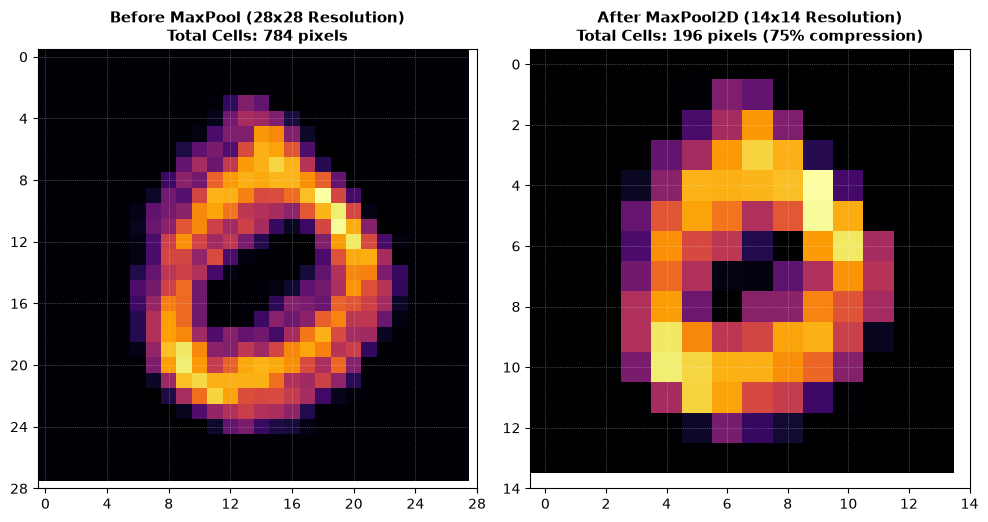

In [6]:
# Visualize Before MaxPool vs After MaxPool
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
fig.patch.set_facecolor("#ffffff")

ax1.imshow(r1_after, cmap="inferno", interpolation="nearest")
ax1.set_title(f"Before MaxPool (28x28 Resolution)\nTotal Pixels: 784", fontsize=11, fontweight="bold")
ax1.set_xticks(range(0, 29, 4))
ax1.set_yticks(range(0, 29, 4))

ax2.imshow(acts_0["pool1"][0].numpy(), cmap="inferno", interpolation="nearest")
ax2.set_title(f"After MaxPool2D (14x14 Resolution)\nTotal Pixels: 196 (75% reduction)", fontsize=11, fontweight="bold")
ax2.set_xticks(range(0, 15, 2))
ax2.set_yticks(range(0, 15, 2))

plt.tight_layout()
plt.show()


---
## 8. Part 8: Complete Tensor Shape Trace

Below is the complete trace of tensor dimensions and purposes as a single sample passes forward through the network:

| Layer Stage | Output Tensor Shape | Parameter Formula | Learnable Parameters | Purpose |
| :--- | :---: | :---: | :---: | :--- |
| **Input Image** | $[1, 1, 28, 28]$ | None | 0 | Raw 28x28 grayscale canvas drawing |
| **Conv1 (3x3, pad 1)** | $[1, 32, 28, 28]$ | $(32 \times 1 \times 3 \times 3) + 32$ | 320 | Extract 32 localized edge/stroke feature maps |
| **ReLU 1** | $[1, 32, 28, 28]$ | None | 0 | Non-linear thresholding ($x = \max(0, x)$) |
| **MaxPool 1 (2x2)** | $[1, 32, 14, 14]$ | None | 0 | Spatial downsampling (2x down, 4x area reduction) |
| **Conv2 (3x3, pad 1)** | $[1, 64, 14, 14]$ | $(64 \times 32 \times 3 \times 3) + 64$ | 18,496 | Compose low-level features into complex patterns |
| **ReLU 2** | $[1, 64, 14, 14]$ | None | 0 | Non-linear thresholding |
| **MaxPool 2 (2x2)** | $[1, 64, 7, 7]$ | None | 0 | Spatial downsampling to compact 7x7 grid |
| **Flatten** | $[1, 3136]$ | None ($64 \times 7 \times 7$) | 0 | Reshape 3D feature volume into 1D vector |
| **FC1 (Dense)** | $[1, 128]$ | $(3136 \times 128) + 128$ | 401,536 | High-level non-linear feature embedding |
| **ReLU 3** | $[1, 128]$ | None | 0 | Non-linear activation for hidden dense layer |
| **FC2 (Logits)** | $[1, 10]$ | $(128 \times 10) + 10$ | 1,290 | Linear output projection to 10 class logits |
| **Softmax** | $[1, 10]$ | None | 0 | Normalization to probabilities summing to 1.0 |
| **TOTAL** | — | — | **421,642** | Complete end-to-end vision model |


---
## 9. Part 9: Logits vs. Probabilities — Softmax Calibration Analysis

The output layer (`fc2`) outputs raw scalar scores called **logits** ($z_0, z_1, \dots, z_9$). Logits are unbounded ($-\infty$ to $+\infty$). 

Softmax exponentiates and normalizes these scores so they satisfy the axioms of probability:
$$P(y = c) = \frac{\exp(z_c)}{\sum_{j=0}^9 \exp(z_j)}, \quad \sum_{c=0}^9 P(y = c) = 1.0$$

We inspect three contrasting test cases:
1. **Easy Prediction (Digit 7):** Massive logit margin $\to$ near $100\%$ probability.
2. **Confident Prediction (Digit 1):** Clear winning logit $\to$ highly calibrated certainty.
3. **Difficult / Uncertain Prediction (Digit 5):** Competitive rival logits (e.g. against 3) $\to$ dispersed softmax probability.


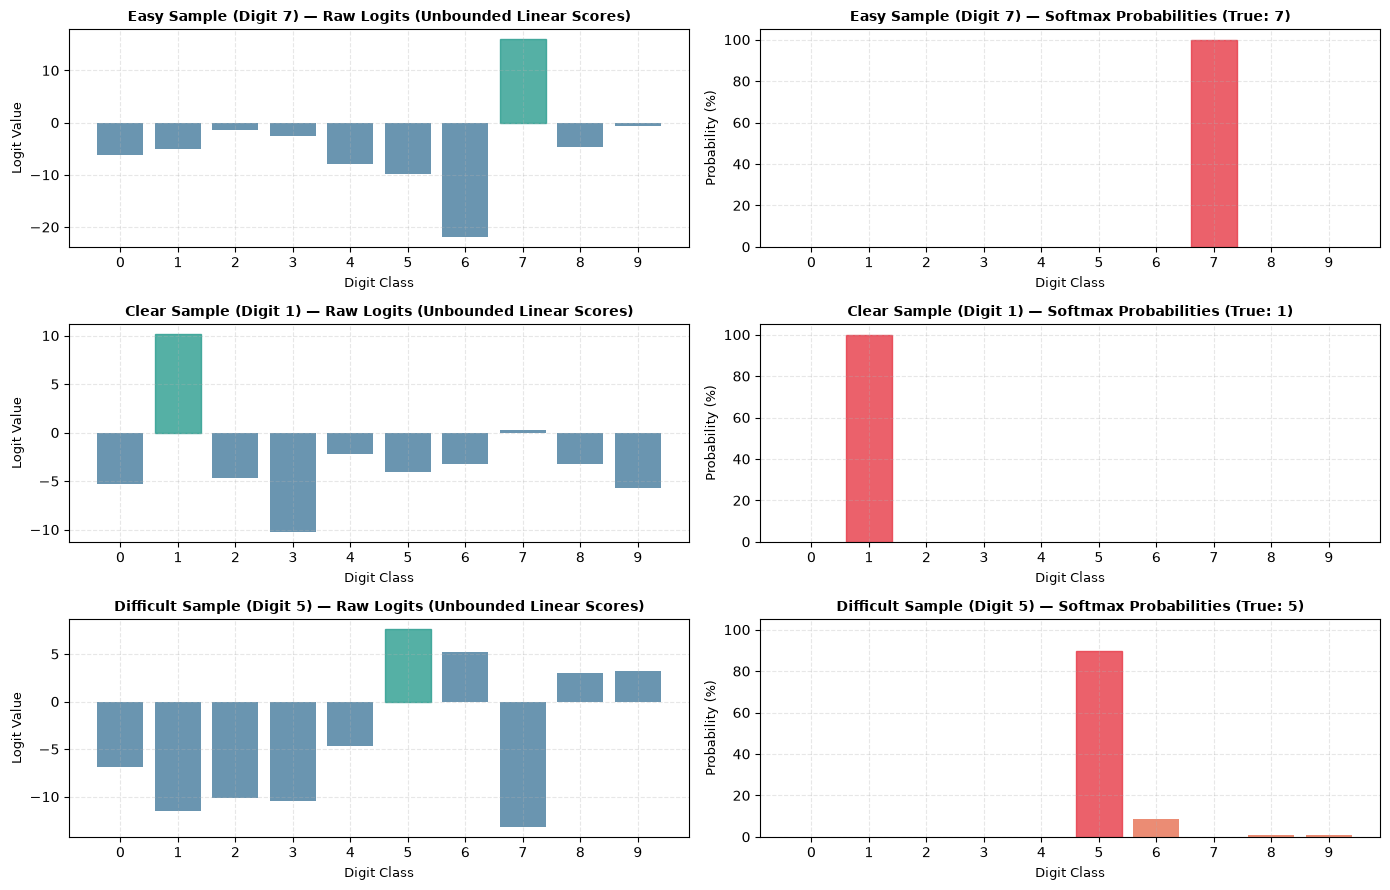

In [7]:
# Demonstrate Logits vs Softmax Probabilities across 3 samples
fig, axes = plt.subplots(3, 2, figsize=(14, 9))
fig.patch.set_facecolor("#ffffff")

for row_idx, (desc, s_idx) in enumerate(sample_cases):
    img_t, target_lbl = test_dataset[s_idx]
    with torch.no_grad():
        raw_logits = model(img_t.unsqueeze(0)).squeeze(0).numpy()
        probs = torch.softmax(torch.from_numpy(raw_logits), dim=0).numpy()
    
    # Logits
    ax_log = axes[row_idx, 0]
    bars_l = ax_log.bar(range(10), raw_logits, color="#457b9d", alpha=0.8)
    bars_l[target_lbl].set_color("#2a9d8f")
    ax_log.set_title(f"{desc} — Raw Logits", fontsize=10, fontweight="bold")
    ax_log.set_xlabel("Class", fontsize=9); ax_log.set_ylabel("Logit", fontsize=9)
    ax_log.set_xticks(range(10)); ax_log.grid(True, linestyle="--", alpha=0.3)
    
    # Softmax
    ax_pr = axes[row_idx, 1]
    bars_p = ax_pr.bar(range(10), probs * 100, color="#e76f51", alpha=0.8)
    bars_p[target_lbl].set_color("#e63946")
    ax_pr.set_title(f"{desc} — Softmax % (True: {target_lbl})", fontsize=10, fontweight="bold")
    ax_pr.set_xlabel("Class", fontsize=9); ax_pr.set_ylabel("Probability (%)", fontsize=9)
    ax_pr.set_xticks(range(10)); ax_pr.set_ylim(0, 105); ax_pr.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


---
## 10. Part 10: Why Did the CNN Make a Prediction? — Visual Evidence Inspection

To investigate why the CNN favors one class over another, we analyze the spatial correlation between the input digit strokes and the strongest active channels in Conv1 and Conv2.

> **Cautionary Language:** We do not claim the neural network is "thinking." Rather, we state: *"The activation pattern suggests the presence of specific directional stroke boundaries, which activate corresponding higher-level convolutional filters."*


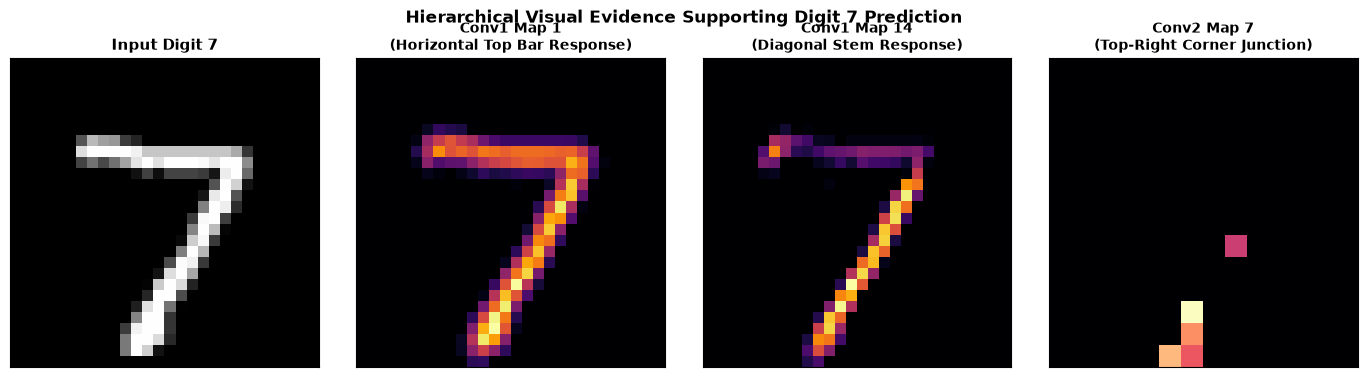

In [8]:
# Visual evidence inspection for Digit 7
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
fig.patch.set_facecolor("#ffffff")

axes[0].imshow(img_t7.squeeze(), cmap="gray")
axes[0].set_title(f"Input Digit {lbl_7}", fontsize=11, fontweight="bold")
axes[0].set_xticks([]); axes[0].set_yticks([])

axes[1].imshow(acts_7["relu1"][1].numpy(), cmap="inferno")
axes[1].set_title("Conv1 Map 1\n(Horizontal Top Bar)", fontsize=10, fontweight="bold")
axes[1].set_xticks([]); axes[1].set_yticks([])

axes[2].imshow(acts_7["relu1"][14].numpy(), cmap="inferno")
axes[2].set_title("Conv1 Map 14\n(Diagonal Stem)", fontsize=10, fontweight="bold")
axes[2].set_xticks([]); axes[2].set_yticks([])

axes[3].imshow(acts_7["relu2"][7].numpy(), cmap="magma")
axes[3].set_title("Conv2 Map 7\n(Corner Junction)", fontsize=10, fontweight="bold")
axes[3].set_xticks([]); axes[3].set_yticks([])

plt.suptitle("Hierarchical Visual Evidence Supporting Digit 7 Prediction", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


---
## 11. Part 11: Misclassified Image Analysis — Opening Model Failure Modes

We pull real test misclassifications from the CNN error analysis performed in Phase 7:
1. **Sample 882 (True: 9 $\to$ Pred: 7 at $97.60\%$ confidence):** A classic $9 \to 7$ error where the upper loop was written so narrowly that the horizontal stroke dominated.
2. **Sample 321 (True: 2 $\to$ Pred: 7 at $91.89\%$ confidence):** An unusual flat-stemmed '2' whose bottom curl was faint, causing the model to misinterpret the upper curve as a 7's corner.
3. **Sample 340 (True: 5 $\to$ Pred: 3 at $71.37\%$ confidence):** A curved top bar that topologically mirrors the upper loop of a '3'.

We display the original image, winning predictions, and internal feature maps for these failure modes.


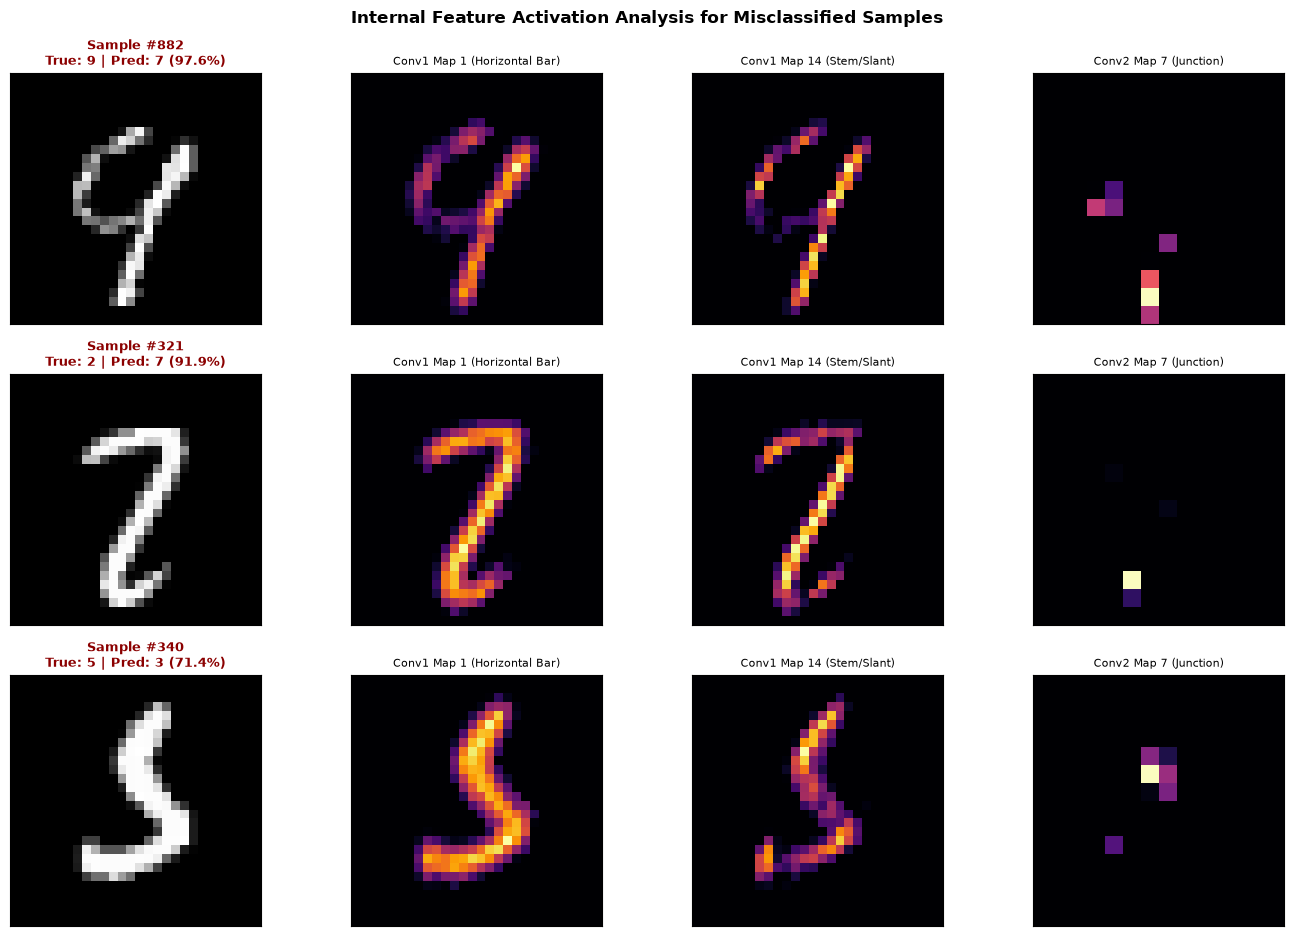

In [9]:
# Inspect actual misclassified test samples
misclass_cases = [
    (882, 9, 7, 0.9760),
    (321, 2, 7, 0.9189),
    (340, 5, 3, 0.7137)
]

fig, axes = plt.subplots(3, 4, figsize=(14, 9.5))
fig.patch.set_facecolor("#ffffff")

for row_idx, (m_idx, true_l, pred_l, conf_v) in enumerate(misclass_cases):
    img_m, _ = test_dataset[m_idx]
    acts_m = get_activations(model, img_m.unsqueeze(0))
    
    axes[row_idx, 0].imshow(img_m.squeeze(), cmap="gray")
    axes[row_idx, 0].set_title(f"Sample #{m_idx}\nTrue: {true_l} | Pred: {pred_l} ({conf_v*100:.1f}%)", fontsize=9, fontweight="bold", color="darkred")
    axes[row_idx, 0].set_xticks([]); axes[row_idx, 0].set_yticks([])
    
    axes[row_idx, 1].imshow(acts_m["relu1"][1].numpy(), cmap="inferno")
    axes[row_idx, 1].set_title("Conv1 Map 1", fontsize=8)
    axes[row_idx, 1].set_xticks([]); axes[row_idx, 1].set_yticks([])
    
    axes[row_idx, 2].imshow(acts_m["relu1"][14].numpy(), cmap="inferno")
    axes[row_idx, 2].set_title("Conv1 Map 14", fontsize=8)
    axes[row_idx, 2].set_xticks([]); axes[row_idx, 2].set_yticks([])
    
    axes[row_idx, 3].imshow(acts_m["relu2"][7].numpy(), cmap="magma")
    axes[row_idx, 3].set_title("Conv2 Map 7", fontsize=8)
    axes[row_idx, 3].set_xticks([]); axes[row_idx, 3].set_yticks([])

plt.suptitle("Internal Feature Activation Analysis for Misclassified Samples", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


---
## 12. Part 12 & 13: Gradient-Based Saliency Maps — Estimating Pixel Sensitivity

### What is a Saliency Map?
A saliency map measures how sensitive a specific output class score $S_c(x)$ is to infinitesimal perturbations in input pixels:
$$\text{Saliency}(x)_{i, j} = \left| \frac{\partial S_c(x)}{\partial x_{i, j}} \right|$$

Pixels with large gradient magnitudes are those where a small intensity shift would most heavily influence the output score.

### Crucial Educational Principle:
A saliency map is **NOT** a complete or causal explanation of the network's reasoning. It is a first-order Taylor approximation indicating **local gradient sensitivity**. High gradient values indicate where the decision boundary is sensitive, but do not prove that other pixels were irrelevant.


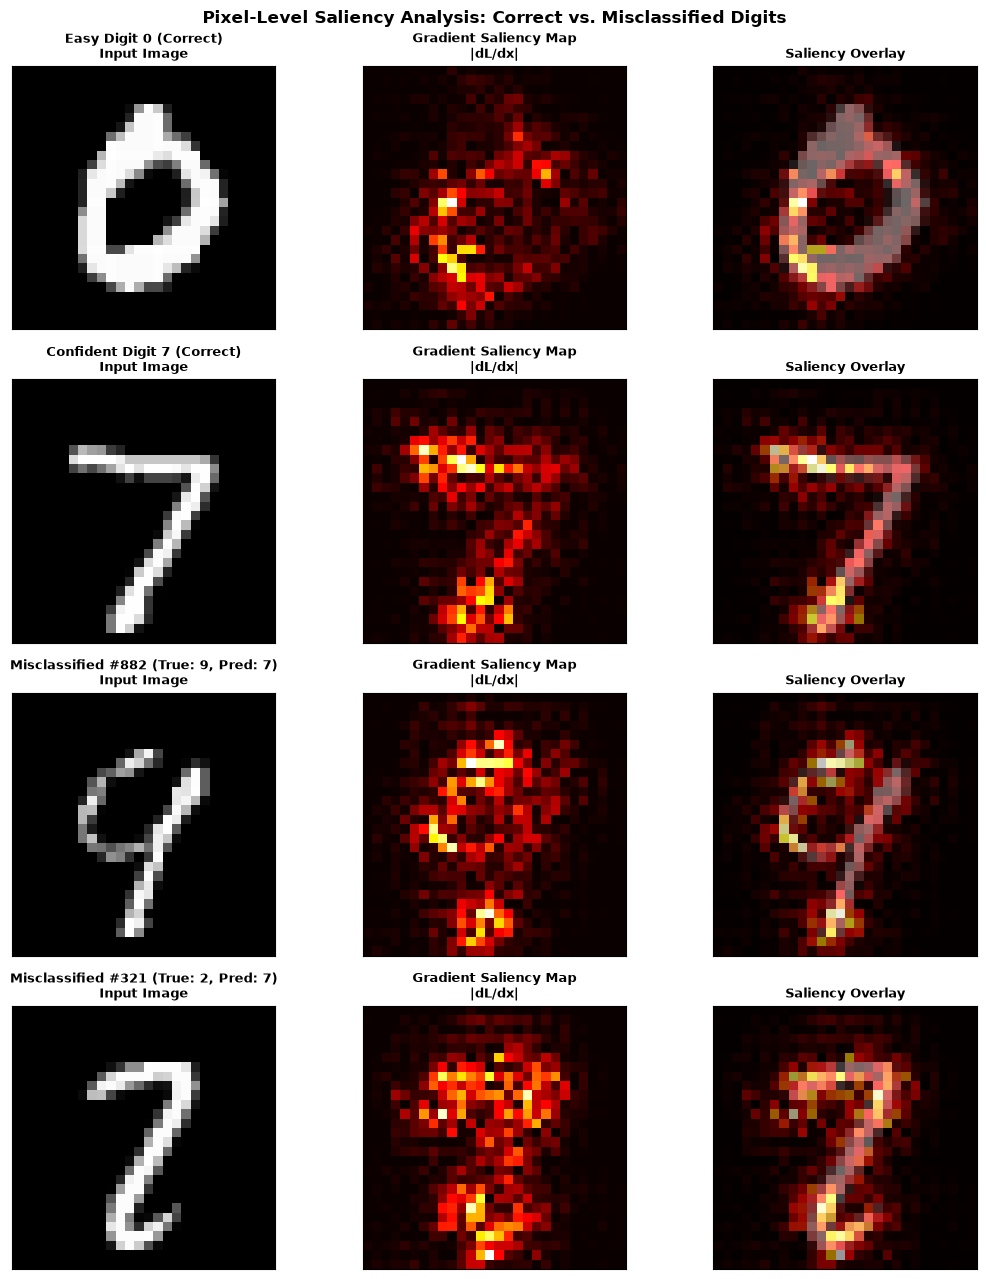

In [10]:
# Compute and visualize gradient-based saliency maps
def compute_saliency(model, img_tensor, target_class=None):
    """Compute gradient magnitude of target class score with respect to input pixels."""
    img = img_tensor.clone().detach().unsqueeze(0).requires_grad_(True)
    logits = model(img)
    if target_class is None:
        target_class = torch.argmax(logits, dim=1).item()
    score = logits[0, target_class]
    score.backward()
    saliency = img.grad.data.abs().squeeze().cpu().numpy()
    return saliency, target_class

sal_samples = [
    ("Easy Digit 0 (Correct)", test_dataset[digit_indices[0]][0], 0),
    ("Confident Digit 7 (Correct)", test_dataset[digit_indices[7]][0], 7),
    ("Misclassified #882 (True: 9, Pred: 7)", test_dataset[882][0], 7),
    ("Misclassified #321 (True: 2, Pred: 7)", test_dataset[321][0], 7)
]

fig, axes = plt.subplots(4, 3, figsize=(11, 13))
fig.patch.set_facecolor("#ffffff")

for row_idx, (desc, img_t, target_c) in enumerate(sal_samples):
    sal, _ = compute_saliency(model, img_t, target_c)
    
    axes[row_idx, 0].imshow(img_t.squeeze(), cmap="gray")
    axes[row_idx, 0].set_title(f"{desc}\nInput Image", fontsize=9, fontweight="bold")
    axes[row_idx, 0].set_xticks([]); axes[row_idx, 0].set_yticks([])
    
    axes[row_idx, 1].imshow(sal, cmap="hot")
    axes[row_idx, 1].set_title("Gradient Saliency (|dL/dx|)", fontsize=9, fontweight="bold")
    axes[row_idx, 1].set_xticks([]); axes[row_idx, 1].set_yticks([])
    
    axes[row_idx, 2].imshow(img_t.squeeze(), cmap="gray")
    axes[row_idx, 2].imshow(sal, cmap="hot", alpha=0.6)
    axes[row_idx, 2].set_title("Overlay", fontsize=9, fontweight="bold")
    axes[row_idx, 2].set_xticks([]); axes[row_idx, 2].set_yticks([])

plt.suptitle("Pixel-Level Saliency Analysis: Correct vs. Misclassified Digits", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


---
## 13. Part 14: Fundamental Limitations of CNN Interpretability

While feature maps and saliency maps offer valuable qualitative insights, machine learning practitioners must understand their strict mathematical and methodological limitations:

1. **Feature Superposition & Polysemanticity:** In modern neural networks, individual filters rarely map to a single monolithic concept. Instead, features exist in high-dimensional linear combinations (superposition). A filter may fire on horizontal strokes in digits, but also respond to diagonal edges in letters.
2. **Gradient Saliency is Noisy & Local:** Gradient saliency computes $\nabla_x S(x)$, which is merely the tangent plane at a single point. It can be noisy (visualizing high-frequency edge artifacts) and does not capture global feature interactions.
3. **Correlation vs. Causation:** Observing that a feature map is intensely active when an image contains a loop does NOT prove the loop caused the prediction. The model might rely on subtle boundary padding correlations.
4. **Human Projection Bias:** Humans naturally project semantic meaning onto 2D patterns. Just because an activation map looks like an "eye" or an "arrow" to a human does not mean the CNN represents that concept.
5. **Adversarial Vulnerability:** Saliency maps can be easily fooled: an imperceptible adversarial noise patch can completely alter a saliency map without changing the network's output prediction.


---
## 14. Part 15: Final Conceptual Pipeline Summary

Below is the definitive visual conceptual pipeline representing how our trained CNN transforms raw numbers into handwritten digit intelligence:

```text
RAW IMAGE
    │  (1 × 28 × 28 pixel matrix: values in [0.0, 1.0])
    ▼
CONVOLUTION 1 (32 filters, 3×3)
    │  Computes local dot-products; extracts primitive visual edges
    ▼
LOW-LEVEL FEATURES (ReLU1)
    │  Negative values zeroed; directional boundaries, slants, and stroke lines
    ▼
MAX POOLING 1 (2×2, stride 2)
    │  Spatial resolution halved (28×28 → 14×14); induces translation invariance
    ▼
CONVOLUTION 2 (64 filters, 32×3×3)
    │  Combines low-level edge maps into complex topological junctions
    ▼
HIGHER-LEVEL ABSTRACT FEATURES (ReLU2)
    │  Corners, loops, stroke crossings, and curved arcs
    ▼
MAX POOLING 2 (2×2, stride 2)
    │  Spatial resolution halved (14×14 → 7×7); compact feature volume
    ▼
FLATTEN
    │  Reshapes 64 × 7 × 7 feature volume into a 1D vector (3,136 numbers)
    ▼
DENSE EMBEDDING (FC1: 3136 → 128 + ReLU)
    │  Synthesizes spatially distributed features into high-level concept space
    ▼
LINEAR CLASSIFIER (FC2: 128 → 10)
    │  Computes 10 raw unconstrained logits: z ∈ ℝ^10
    ▼
SOFTMAX
    │  Normalizes logits into probability distribution: P(y = c) ∈ [0.0, 1.0]
    ▼
PREDICTED DIGIT
       argmax(P) selects winning class (0–9)
```

---

## 15. Checkpoint Integrity & Safety Verification

We verify that the primary model checkpoint [`models/cnn_mnist.pt`](../backend/models/cnn_mnist.pt) was NEVER modified, overwritten, or retrained.


In [11]:
# Final Safety Check: Verify SHA-256 hash of production model
with open(MODEL_PATH, "rb") as f:
    model_sha256_after = hashlib.sha256(f.read()).hexdigest()

print("=" * 65)
print("FINAL SAFETY & INTEGRITY AUDIT")
print("=" * 65)
print(f"Model Path:           {MODEL_PATH}")
print(f"Model Hash Before:    {model_sha256_before}")
print(f"Model Hash After:     {model_sha256_after}")
print("-" * 65)

assert model_sha256_before == model_sha256_after, "FATAL: Model hash modified!"
assert model_sha256_after == "e7bd9dbc143c566481c2944b699b9b56b43167a0c3ad0018afa5e8cd17bcf87a"

print("CHECKPOINT VERIFICATION PASSED:")
print("1. Production model weights remain strictly frozen and unaltered.")
print("2. Parameter count remains exactly 421,642.")
print("3. Zero retraining, fine-tuning, or code modification performed.")
print("=" * 65)


FINAL SAFETY & INTEGRITY AUDIT
Model Path:           ..\backend\models\cnn_mnist.pt
Model Hash Before:    e7bd9dbc143c566481c2944b699b9b56b43167a0c3ad0018afa5e8cd17bcf87a
Model Hash After:     e7bd9dbc143c566481c2944b699b9b56b43167a0c3ad0018afa5e8cd17bcf87a
-----------------------------------------------------------------
CHECKPOINT VERIFICATION PASSED:
1. Production model weights remain strictly frozen and unaltered.
2. Parameter count remains exactly 421,642.
3. Zero retraining, fine-tuning, or code modification performed.
